# СИЛАНТ · 04. Модели и прогноз на 4 квартала

**Горизонт:** 4 квартала после последнего факта в файле (сейчас II кв. 2026 — I кв. 2027). **Уровни:** 10 базовых рядов (по 4 крупных сегмента + «5,5 т+» у ДВС и электро) → ДВС, Электро → Рынок.

**Модели** (все на логарифме сезонно скорректированного ряда; сезонный профиль — общий для всех рядов, оценивается по электро и только на обучающих данных: на этапе 02 сегменты не отличались от общего профиля, а сезонность ДВС не идентифицируется из-за слома внутри 2025 года):
| Модель | Суть | Параметры |
|---|---|---|
| Наивный (бенчмарк) | уровень последнего квартала без сезонности × сезонный коэффициент | 0 |
| Сезонный наивный (бенчмарк) | тот же квартал год назад | 0 |
| ETS(A,N,N) | экспоненциальное сглаживание уровня, без тренда (тренд на 13 точках опасен) | α |
| ARX-ставка | log-уровень = a + b·ключевая ставка(t−2) + AR(1)-ошибка; b сжимается к общему значению по сегментам типа (эмпирический Байес) и ограничен b ≤ 0 (рост ставки не может увеличивать спрос) | a, b, φ |
| Комбинация | равновзвешенное среднее логарифмов Наивный + ETS + ARX (веса не подбираются → не переобучаются) | — |

**Интервалы:** совместная бутстреп-симуляция (остатки всех рядов берутся из одного исторического квартала → сохраняется корреляция сегментов) + неопределённость сезонных коэффициентов и коэффициента ставки; каждая траектория согласуется с иерархией (WLS). Ширина калибруется по rolling-origin: множитель подбирается так, чтобы 80 %-ные интервалы накрывали ~80 % фактов.

**Ставка в прогнозе на 4 квартала — фактическая:** при лаге 2 для II кв. 2026 — I кв. 2027 нужны ставки IV кв. 2025 — III кв. 2026, и все они уже известны. Сценарии по ставке нужны только для горизонта 8 кварталов.

---
**Место в пайплайне:** шаг 4 из 6. Предыдущий: 03 — внешние факторы. Следующий: 05 — сценарии. Запуск всех шагов: `python update.py`.

**Вход:** `data/processed/market_long.csv`, `macro_quarterly_wide.csv`; `data/external/manual/scenarios.csv` (ставка, если факта нет).

**Выход:** `data/processed/backtest_rolling_origin.csv`, `interval_calibration.json`, `forecast_4q*.csv`, `forecast_bias_backtest.csv`, `segment_yoy_check.csv`; графики `30–33_*.png`.

**Содержание:** 0. Настройка · 1. Rolling-origin валидация · 2. Калибровка интервалов · 3. Прогноз на 4 квартала · 4. Доля электропогрузчиков · 5. Что внутри моделей · 6. Выводы · Источники

## 0. Настройка
Импорт библиотек, пути (относительно корня проекта), параметры и фиксированный seed для случайных чисел. Общие функции вынесены в модули `src/`, чтобы ноутбук содержал только логику анализа.

In [1]:
import sys
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from silant_data import load_market
from silant_ts import build_series
from silant_forecast import forecast_all, rolling_origin, summarize, share_draws, MODELS, BENCH

SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
OUT = ROOT / "data/processed"
FIG = ROOT / "reports/figures"
COL = {"ДВС": "#eb6834", "Электро": "#2a78d6", "Рынок": "#52514e"}
MCOL = {
    "Наивный": "#8a8984",
    "Сезонный наивный": "#c3c2b7",
    "ETS": "#1baf7a",
    "ARX-ставка": "#4a3aa7",
    "Комбинация": "#e34948",
}
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 150,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.6,
        "axes.edgecolor": "#8a8984",
        "font.size": 10,
        "axes.titleweight": "bold",
        "axes.titlesize": 11,
        "lines.linewidth": 2,
    }
)
thous = mt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " "))
pctf = mt.PercentFormatter(1.0, decimals=0)


def qlab(p):
    p = pd.Period(p, freq="Q")
    return f"{('I', 'II', 'III', 'IV')[p.quarter - 1]} кв. {p.year}"


SOURCE_NOTE = "Источники: данные заказчика, Банк России, Росстат; расчёты автора."
UNITS = {"31_fan_market": "Продажи, шт.", "33_e_share_fan": "Доля электропогрузчиков"}


def save(fig, name):
    # подпись оси Y (единицы) там, где её нет, и источник данных под рисунком
    unit = UNITS.get(name)
    if unit:
        for ax in fig.axes:
            if not ax.get_ylabel() and ax.get_label() != "<colorbar>":
                ax.set_ylabel(unit)
    fig.canvas.draw()
    bottom = fig.get_tightbbox(fig.canvas.get_renderer()).y0 / fig.get_figheight()
    fig.text(0.01, bottom - 0.02, SOURCE_NOTE, fontsize=8, color="#555555", ha="left", va="top")
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()


def col_of(n):
    return COL.get(n, COL["ДВС"] if n.startswith("ДВС") else COL["Электро"])


S = build_series(load_market(ROOT / "data/raw/silant_forklift_market.xlsx")[0])
W = pd.read_csv(OUT / "macro_quarterly_wide.csv", index_col=0)
W.index = pd.PeriodIndex(W.index, freq="Q")
LAST = S.index.max()
H = 4
from silant_scenarios import kr_for_forecast

KR, KR_NOTES = kr_for_forecast(W, ROOT, LAST, H=H)
for n_ in KR_NOTES:
    print("⚠️", n_)
KEY = ["Рынок", "ДВС", "Электро"]
BIG = [c for c in S.columns if " " in c and "5,5" not in c]
print(
    "Последний факт:",
    LAST,
    "| прогноз:",
    [qlab(q) for q in pd.period_range(LAST + 1, periods=H, freq="Q")],
)
print("Ставка, используемая с лагом 2:", KR.loc[LAST - 1 : LAST + H - 2].round(2).to_dict())

Последний факт: 2026Q1 | прогноз: ['II кв. 2026', 'III кв. 2026', 'IV кв. 2026', 'I кв. 2027']
Ставка, используемая с лагом 2: {Period('2025Q4', 'Q-DEC'): 16.59, Period('2026Q1', 'Q-DEC'): 15.71, Period('2026Q2', 'Q-DEC'): 14.62, Period('2026Q3', 'Q-DEC'): 14.07}


## 1. Rolling-origin валидация
Начала прогноза: IV кв. 2024 … предпоследний доступный квартал (обучение от 8 точек, растущее окно), горизонты 1–4. Метрика — средняя |log(факт/прогноз)| (≈ средняя ошибка в %), для доли электро — средняя абсолютная ошибка в п. п.

Ключевая ставка в проверке не «подсматривает» в будущее: после начала прогноза она замораживается на последнем известном значении (с лагом 2 квартала это затрагивает горизонты 3–4). До 15.10.2026 проверка использовала фактическую ставку; после исправления ошибка ARX на этих горизонтах чуть ниже, выводы те же.

⚠️ В окно попадает слом II кв. 2025: проверка измеряет в первую очередь то, как модели переживают структурный шок. Точек мало (5 начал, 14 пар «прогноз–факт» на ряд), разница в несколько п. п. между моделями — в пределах шума.

In [2]:
FIRST_O = pd.Period("2024Q4", freq="Q")
LAST_O = LAST - 1
bt = rolling_origin(S, KR, FIRST_O, LAST_O, H=H, n_sim=800, seed=SEED)
rec = bt[bt.src == "rec"]
tab = rec[rec.node.isin(KEY + BIG + ["Доля электро"])].assign(
    group=lambda d: np.where(
        d.node.isin(KEY),
        d.node,
        np.where(d.node == "Доля электро", "Доля электро, п.п.", "Крупные сегменты (8)"),
    )
)
err = tab.pivot_table(index="model", columns="group", values="abs_log_err", aggfunc="mean")[
    ["Рынок", "ДВС", "Электро", "Крупные сегменты (8)", "Доля электро, п.п."]
]
skill = 1 - err / err.loc[BENCH]
display(
    err.style.format("{:.1%}")
    .highlight_min(axis=0, props="font-weight:bold")
    .set_caption("Средняя ошибка (согласованные прогнозы)")
)
display(skill.style.format("{:+.0%}").set_caption("Выигрыш к наивному (+ = лучше)"))
bt.to_csv(OUT / "backtest_rolling_origin.csv", index=False, encoding="utf-8-sig")

group,Рынок,ДВС,Электро,Крупные сегменты (8),"Доля электро, п.п."
model,,,,,
ARX-ставка,29.2%,52.8%,18.3%,40.6%,7.8%
ETS,31.5%,53.7%,21.6%,39.8%,8.2%
Комбинация,29.2%,50.1%,19.9%,38.1%,7.3%
Наивный,33.1%,53.5%,23.9%,41.7%,7.5%
Сезонный наивный,41.1%,75.6%,23.3%,51.8%,12.2%


group,Рынок,ДВС,Электро,Крупные сегменты (8),"Доля электро, п.п."
model,,,,,
ARX-ставка,+12%,+1%,+23%,+3%,-5%
ETS,+5%,-0%,+9%,+5%,-10%
Комбинация,+12%,+6%,+16%,+9%,+2%
Наивный,+0%,+0%,+0%,+0%,+0%
Сезонный наивный,-24%,-41%,+3%,-24%,-63%


Сводка ошибок: средняя ошибка каждой модели по рынку, типам, сегментам и доле электро, выигрыш относительно наивного прогноза и ошибка по горизонту.

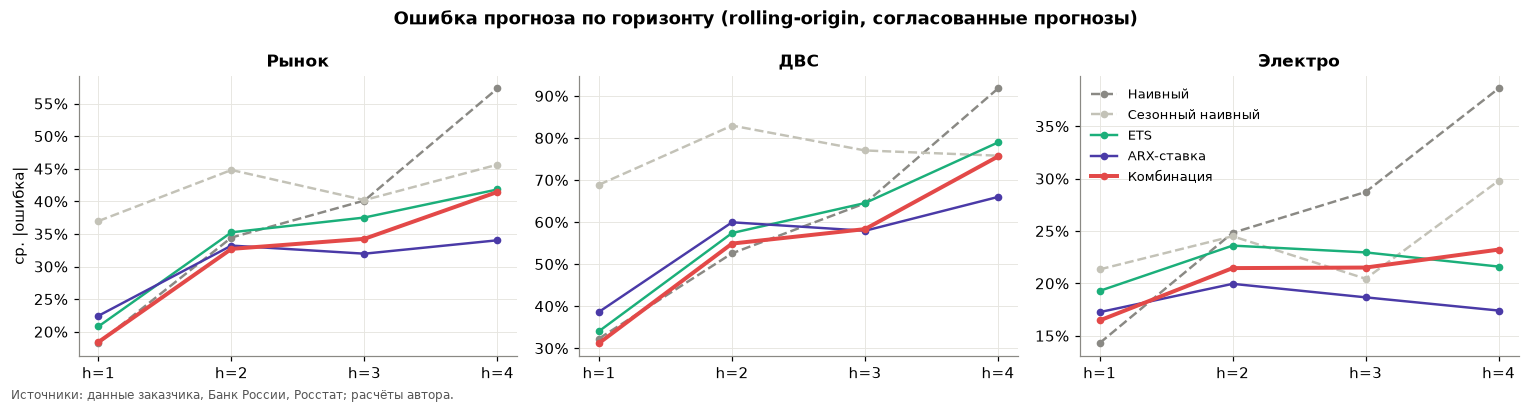

Эффект согласования (все ключевые ряды и крупные сегменты):


src,base,rec
model,,
ARX-ставка,38.6%,38.6%
ETS,38.4%,38.7%
Комбинация,36.7%,36.7%
Наивный,40.9%,40.4%
Сезонный наивный,50.7%,50.4%


In [3]:
eh = rec[rec.node.isin(KEY)].pivot_table(
    index=["node", "h"], columns="model", values="abs_log_err", aggfunc="mean"
)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=False)
for ax, n in zip(axes, KEY):
    d = eh.loc[n]
    for m in MODELS:
        ax.plot(
            d.index,
            d[m],
            marker="o",
            ms=4,
            color=MCOL[m],
            lw=2.6 if m == "Комбинация" else 1.6,
            ls="--" if "наивный" in m.lower() else "-",
            label=m,
        )
    ax.set_title(n)
    ax.set_xticks([1, 2, 3, 4], ["h=1", "h=2", "h=3", "h=4"])
    ax.yaxis.set_major_formatter(pctf)
axes[0].set_ylabel("ср. |ошибка|")
axes[-1].legend(frameon=False, fontsize=8.5)
fig.suptitle(
    "Ошибка прогноза по горизонту (rolling-origin, согласованные прогнозы)", fontweight="bold"
)
fig.tight_layout()
save(fig, "30_backtest_horizon")

base_vs_rec = bt[bt.node.isin(KEY + BIG)].pivot_table(
    index="model", columns="src", values="abs_log_err", aggfunc="mean"
)
print("Эффект согласования (все ключевые ряды и крупные сегменты):")
display(base_vs_rec.style.format("{:.1%}"))

## 2. Калибровка интервалов
Остатки внутри выборки не содержат информации о структурных сломах, поэтому модельные интервалы получаются узкими. Подбираем множитель ширины k (лог-отклонения от медианы × k) — наименьший из сетки, при котором 80 %-ный интервал накрывает ≥80 % фактов в rolling-origin. Калибровка сделана на тех же 5 началах, на которых потом проверяется покрытие, поэтому итоговое покрытие — оптимистичная оценка.

In [4]:
grid = [1.0, 1.25, 1.5, 1.75, 2.0, 2.25, 2.5, 3.0]
cov = {}
for k in grid:
    b = rolling_origin(
        S, KR, FIRST_O, LAST_O, H=H, n_sim=500, seed=SEED, infl={m: k for m in MODELS}
    )
    d = b[(b.src == "rec") & b.node.isin(KEY + BIG)]
    cov[k] = d.groupby("model")[["in80", "in95"]].mean()
cov80 = pd.DataFrame({k: v.in80 for k, v in cov.items()})
cov95 = pd.DataFrame({k: v.in95 for k, v in cov.items()})
INFL = {m: next((k for k in grid if cov80.loc[m, k] >= 0.8), grid[-1]) for m in MODELS}
print("Множители ширины:", INFL)
import json

(OUT / "interval_calibration.json").write_text(
    json.dumps(INFL, ensure_ascii=False), encoding="utf-8"
)
calib = pd.DataFrame(
    {
        "k": pd.Series(INFL),
        "покрытие 80 % до": cov80[1.0],
        "покрытие 80 % после": pd.Series({m: cov80.loc[m, INFL[m]] for m in MODELS}),
        "покрытие 95 % до": cov95[1.0],
        "покрытие 95 % после": pd.Series({m: cov95.loc[m, INFL[m]] for m in MODELS}),
    }
)
calib.style.format({c: "{:.0%}" for c in calib.columns if c != "k"})

Множители ширины: {'Наивный': 1.0, 'Сезонный наивный': 1.5, 'ETS': 1.5, 'ARX-ставка': 1.5, 'Комбинация': 1.5}


,k,покрытие 80 % до,покрытие 80 % после,покрытие 95 % до,покрытие 95 % после
ARX-ставка,1.500000,63%,82%,84%,95%
ETS,1.500000,62%,82%,81%,94%
Комбинация,1.500000,68%,84%,82%,95%
Наивный,1.000000,81%,81%,92%,92%
Сезонный наивный,1.500000,62%,85%,63%,86%


## 3. Прогноз на 4 квартала

In [5]:
MAIN = "Комбинация"
fc = forecast_all(S, KR, LAST, H=H, n_sim=4000, seed=SEED, infl=INFL)
fut = fc["fut"]
sims = fc["rec"][MAIN]
# проверка согласованности каждой траектории
for t in ["ДВС", "Электро"]:
    parts = sum(sims[b] for b in fc["bottom"] if b.startswith(t + " "))
    assert np.allclose(parts, sims[t]), t
assert np.allclose(sims["ДВС"] + sims["Электро"], sims["Рынок"])
print(
    "Согласованность: сумма сегментов = тип, сумма типов = рынок — во всех",
    len(sims["Рынок"]),
    "траекториях",
)
print(
    "Центральный прогноз — медиана распределения (устойчива к правой асимметрии). Медианы, в отличие от траекторий, не складываются точно; средние (mean) в CSV — аддитивны."
)

summ = summarize(sims, fut)
summ["model"] = MAIN
allm = pd.concat([summarize(fc["rec"][m], fut).assign(model=m) for m in MODELS])
allm.to_csv(OUT / "forecast_4q_all_models.csv", index=False, encoding="utf-8-sig")
summ.to_csv(OUT / "forecast_4q.csv", index=False, encoding="utf-8-sig")

# сумма за 4 квартала (для плана на год вперёд)
last4 = S.iloc[-4:].sum()
yr = pd.DataFrame(
    {
        n: {
            "факт: последние 4 кв.": last4[n],
            "прогноз: среднее": sims[n].sum(1).mean(),
            "P10": np.quantile(sims[n].sum(1), 0.1),
            "P50": np.quantile(sims[n].sum(1), 0.5),
            "P90": np.quantile(sims[n].sum(1), 0.9),
            "P2.5": np.quantile(sims[n].sum(1), 0.025),
            "P97.5": np.quantile(sims[n].sum(1), 0.975),
        }
        for n in fc["nodes"]
    }
).T
yr["изм. к последним 4 кв. (по медиане)"] = yr["P50"] / yr["факт: последние 4 кв."] - 1
yr.to_csv(OUT / "forecast_4q_total.csv", encoding="utf-8-sig")
order = (
    KEY
    + [b for b in fc["bottom"] if b.startswith("ДВС")]
    + [b for b in fc["bottom"] if b.startswith("Электро")]
)
yr.loc[order].style.format(
    {c: (lambda v: f"{v:,.0f}".replace(",", " ")) for c in yr.columns if "изм" not in c}
    | {"изм. к последним 4 кв. (по медиане)": "{:+.0%}"}
)

Согласованность: сумма сегментов = тип, сумма типов = рынок — во всех 4000 траекториях
Центральный прогноз — медиана распределения (устойчива к правой асимметрии). Медианы, в отличие от траекторий, не складываются точно; средние (mean) в CSV — аддитивны.


,факт: последние 4 кв.,прогноз: среднее,P10,P50,P90,P2.5,P97.5,изм. к последним 4 кв. (по медиане)
Рынок,75 990,91 473,64 852,89 221,120 402,53 670,141 031,+17%
ДВС,21 610,31 326,15 756,29 903,49 629,10 889,58 275,+38%
Электро,54 380,60 146,42 275,58 724,80 210,35 942,93 607,+8%
"ДВС 1–1,8 т",5 860,8 492,3 455,7 542,14 651,2 435,20 251,+29%
"ДВС 2–2,5 т",4 830,7 043,3 053,6 748,11 405,1 794,13 656,+40%
"ДВС 3–3,5 т",8 440,12 635,5 201,11 624,22 105,3 421,26 895,+38%
"ДВС 3,8–5 т",1 580,1 965,1 006,1 784,3 159,783,4 177,+13%
"ДВС 5,5 т+",900,1 191,656,1 116,1 828,514,2 279,+24%
"Электро 1–1,8 т",24 570,27 716,19 054,27 152,37 381,15 832,43 664,+11%
"Электро 2–2,5 т",14 290,17 468,10 718,16 999,24 636,8 262,29 735,+19%


Итоговая таблица прогноза на 4 квартала по рынку и типам: медиана, 80 %- и 95 %-ные интервалы, изменение к последним 4 кварталам факта.

In [6]:
qt = summ[summ.node.isin(KEY)].copy()
qt["кв"] = qt.quarter.map(qlab)
qt["прогноз (медиана)"] = qt["q500"].round(-1)
qt["80 %-ный интервал"] = [
    f"{a:,.0f} – {b:,.0f}".replace(",", " ") for a, b in zip(qt.q100, qt.q900)
]
qt["95 %-ный интервал"] = [
    f"{a:,.0f} – {b:,.0f}".replace(",", " ") for a, b in zip(qt.q025, qt.q975)
]
qt.pivot(index="node", columns="кв", values=["прогноз (медиана)", "80 %-ный интервал"]).loc[
    KEY
].reindex(columns=[qlab(q) for q in fut], level=1)

прогноз (медиана)                                     80 %-ный интервал                                                   
кв            II кв. 2026 III кв. 2026 IV кв. 2026 I кв. 2027       II кв. 2026     III кв. 2026      IV кв. 2026       I кв. 2027
node                                                                                                                              
Рынок             23400.0      21090.0     24530.0    18400.0   16 561 – 33 028  14 222 – 30 897  15 814 – 38 013  11 368 – 28 869
ДВС                8000.0       6970.0      8150.0     5980.0    3 599 – 11 789   3 146 – 12 401   3 312 – 16 351   2 359 – 13 108
Электро           16040.0      13970.0     15840.0    11630.0   10 722 – 22 528   9 044 – 20 740  10 174 – 24 732   7 203 – 18 838

Веерный график: факт и прогноз с интервалами для рынка, ДВС и электро.

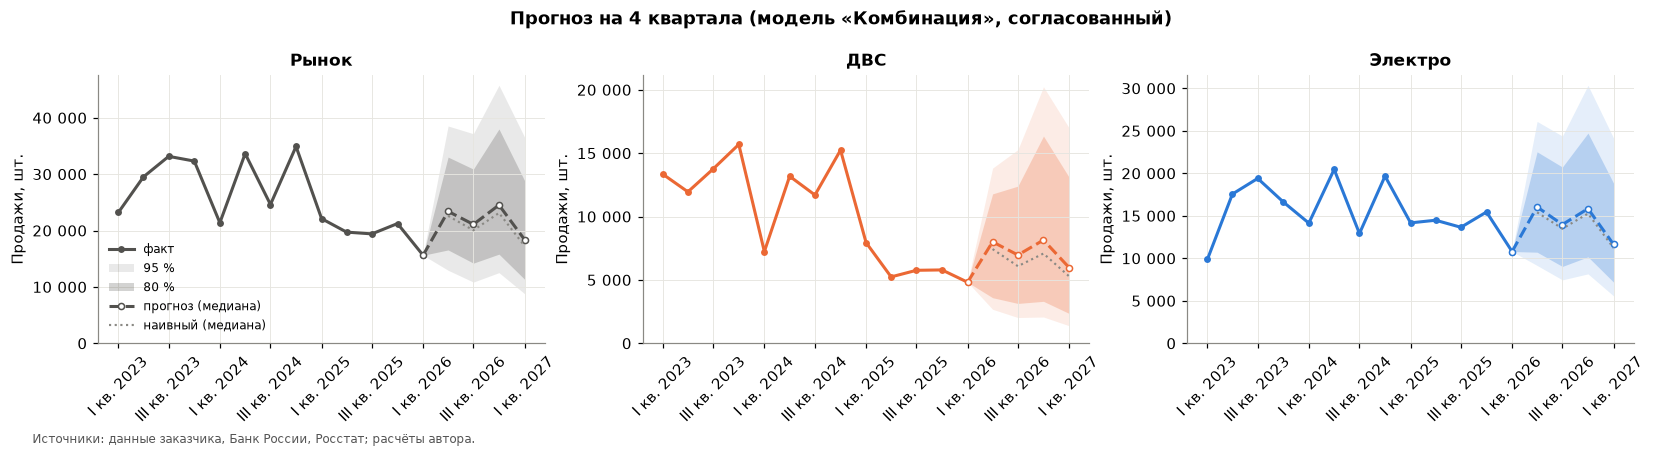

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
hist = S.index.to_timestamp()
for ax, n in zip(axes, KEY):
    d = summ[summ.node == n]
    x = pd.PeriodIndex(d.quarter, freq="Q").to_timestamp()
    ax.plot(hist, S[n], color=col_of(n), marker="o", ms=3.5, label="факт")
    xx = [hist[-1]] + list(x)
    ax.fill_between(
        xx,
        [S[n].iloc[-1]] + list(d.q025),
        [S[n].iloc[-1]] + list(d.q975),
        color=col_of(n),
        alpha=0.12,
        lw=0,
        label="95 %",
    )
    ax.fill_between(
        xx,
        [S[n].iloc[-1]] + list(d.q100),
        [S[n].iloc[-1]] + list(d.q900),
        color=col_of(n),
        alpha=0.25,
        lw=0,
        label="80 %",
    )
    ax.plot(
        xx,
        [S[n].iloc[-1]] + list(d["q500"]),
        color=col_of(n),
        ls="--",
        marker="o",
        ms=4,
        mfc="white",
        label="прогноз (медиана)",
    )
    nv = allm[(allm.node == n) & (allm.model == "Наивный")]
    ax.plot(x, nv["q500"], color="#8a8984", ls=":", lw=1.4, label="наивный (медиана)")
    ax.set_title(n)
    ax.yaxis.set_major_formatter(thous)
    ax.set_ylim(bottom=0)
    ticks = list(S.index[::2]) + list(fut[1::2])
    ax.set_xticks([t.to_timestamp() for t in ticks], [qlab(t) for t in ticks], rotation=45)
axes[0].legend(frameon=False, fontsize=8, loc="lower left")
fig.suptitle(f"Прогноз на 4 квартала (модель «{MAIN}», согласованный)", fontweight="bold")
fig.tight_layout()
save(fig, "31_fan_market")

Прогноз по сегментам за 4 квартала: медиана и интервалы в сравнении с фактом последних 4 кварталов.

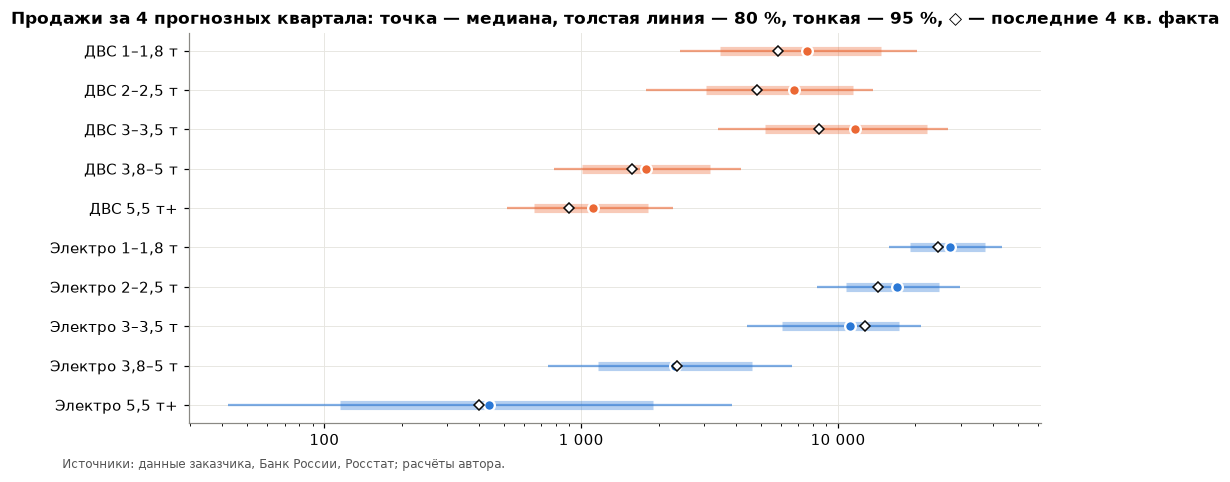

In [8]:
segs = [b for b in order if b not in KEY]
fig, ax = plt.subplots(figsize=(10, 4.6))
y = np.arange(len(segs))[::-1]
for yi, n in zip(y, segs):
    r = yr.loc[n]
    c = col_of(n)
    ax.hlines(yi, r["P10"], r["P90"], color=c, lw=6, alpha=0.35)
    ax.hlines(yi, r["P2.5"], r["P97.5"], color=c, lw=1.5, alpha=0.6)
    ax.plot(r["P50"], yi, "o", color=c, ms=7, mec="white", mew=1.5)
    ax.plot(r["факт: последние 4 кв."], yi, "D", color="#0b0b0b", ms=5, mfc="white")
ax.set_yticks(y, segs)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(thous)
ax.set_title(
    "Продажи за 4 прогнозных квартала: точка — медиана, толстая линия — 80 %, тонкая — 95 %, ◇ — последние 4 кв. факта"
)
save(fig, "32_segments_4q")

## 4. Доля электропогрузчиков

In [9]:
sh = S["Электро"] / S["Рынок"]
shd = share_draws(sims)
share_q = pd.DataFrame(
    {
        "кв": [qlab(q) for q in fut],
        "медиана": np.median(shd, 0),
        "P10": np.quantile(shd, 0.1, 0),
        "P90": np.quantile(shd, 0.9, 0),
        "P2.5": np.quantile(shd, 0.025, 0),
        "P97.5": np.quantile(shd, 0.975, 0),
    }
)
sh4 = sims["Электро"].sum(1) / sims["Рынок"].sum(1)
print(
    f"Доля электро за 4 прогнозных квартала: медиана {np.median(sh4):.1%}, 80%: {np.quantile(sh4, 0.1):.1%}–{np.quantile(sh4, 0.9):.1%}, "
    f"95%: {np.quantile(sh4, 0.025):.1%}–{np.quantile(sh4, 0.975):.1%}; факт за последние 4 кв.: {S['Электро'].iloc[-4:].sum() / S['Рынок'].iloc[-4:].sum():.1%}"
)
share_q.to_csv(OUT / "forecast_4q_e_share.csv", index=False, encoding="utf-8-sig")

# отдельные модели доли (бэктест)
lg = np.log(sh / (1 - sh))


def holt_damped(yv, phi=0.8):
    best = None
    for a in np.linspace(0.1, 1, 10):
        for b in np.linspace(0, 0.5, 6):
            l, t = yv[0], yv[1] - yv[0]
            e = []
            for v in yv[1:]:
                f = l + phi * t
                e.append(v - f)
                ln = a * v + (1 - a) * f
                t = b * (ln - l) + (1 - b) * phi * t
                l = ln
            s_ = np.sum(np.square(e))
            if best is None or s_ < best[0]:
                best = (s_, l, t)
    return best[1], best[2]


rows = []
for o in pd.period_range(FIRST_O, LAST_O, freq="Q"):
    tr = sh[:o]
    l, t = holt_damped(lg[:o].to_numpy())
    for h in range(1, H + 1):
        q = o + h
        if q not in sh.index:
            continue
        f = l + sum(0.8**i for i in range(1, h + 1)) * t
        rows += [
            ("доля: наивная (последний кв.)", h, abs(sh[q] - tr.iloc[-1])),
            ("доля: среднее 4 кв.", h, abs(sh[q] - tr.iloc[-4:].mean())),
            ("доля: логит-Холт с затуханием", h, abs(sh[q] - 1 / (1 + np.exp(-f)))),
        ]
sb = pd.DataFrame(rows, columns=["метод", "h", "err"])
imp = rec[rec.node == "Доля электро"].groupby(["model", "h"]).abs_log_err.mean().reset_index()
imp["метод"] = "из согласованного прогноза: " + imp.model
sb = pd.concat([sb, imp.rename(columns={"abs_log_err": "err"})[["метод", "h", "err"]]])
st = sb.pivot_table(index="метод", columns="h", values="err")
st["среднее"] = st.mean(1)
st.sort_values("среднее").style.format("{:.1f}", subset=None).format(
    lambda v: f"{v * 100:.1f} п.п."
)

Доля электро за 4 прогнозных квартала: медиана 66.3%, 80%: 54.2%–79.0%, 95%: 48.5%–84.5%; факт за последние 4 кв.: 71.6%


h,1,2,3,4,среднее
метод,,,,,
доля: наивная (последний кв.),5.2 п.п.,6.3 п.п.,9.0 п.п.,10.7 п.п.,7.8 п.п.
из согласованного прогноза: Комбинация,4.9 п.п.,7.3 п.п.,8.5 п.п.,11.8 п.п.,8.1 п.п.
из согласованного прогноза: Наивный,5.3 п.п.,6.5 п.п.,9.5 п.п.,12.1 п.п.,8.3 п.п.
из согласованного прогноза: ARX-ставка,5.7 п.п.,8.6 п.п.,8.5 п.п.,10.8 п.п.,8.4 п.п.
из согласованного прогноза: ETS,5.7 п.п.,8.4 п.п.,9.2 п.п.,12.9 п.п.,9.0 п.п.
доля: логит-Холт с затуханием,6.4 п.п.,8.6 п.п.,11.7 п.п.,13.1 п.п.,9.9 п.п.
доля: среднее 4 кв.,7.3 п.п.,10.2 п.п.,11.1 п.п.,12.3 п.п.,10.2 п.п.
из согласованного прогноза: Сезонный наивный,11.0 п.п.,13.5 п.п.,13.5 п.п.,10.9 п.п.,12.2 п.п.


Доля электропогрузчиков на графике: факт и прогноз с интервалами.

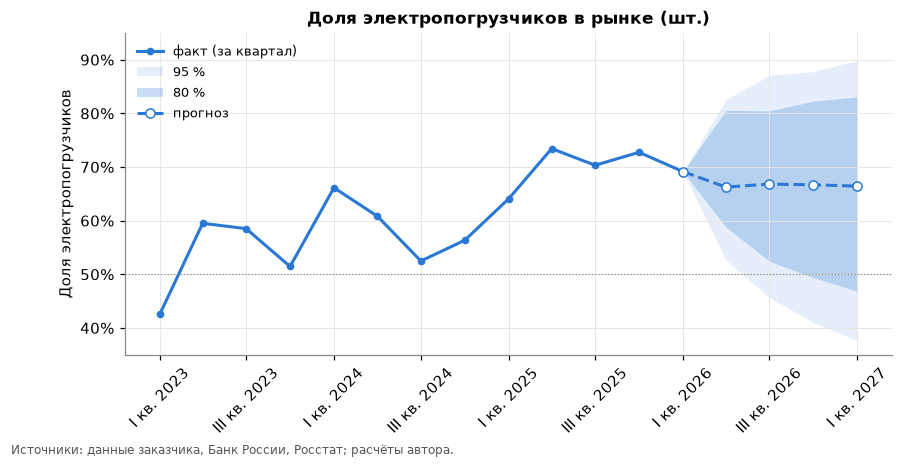

,"факт, последние 4 кв.",прогноз: медиана,P10,P90
"1–1,8 т",81%,78%,68%,87%
"2–2,5 т",75%,71%,59%,85%
"3–3,5 т",60%,49%,26%,73%
"3,8–5 т",60%,60%,33%,72%
"5,5 т+",31%,27%,8%,68%


In [10]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(
    S.index.to_timestamp(), sh, color=COL["Электро"], marker="o", ms=4, label="факт (за квартал)"
)
x = [S.index[-1].to_timestamp()] + list(fut.to_timestamp())
ax.fill_between(
    x,
    [sh.iloc[-1]] + list(share_q["P2.5"]),
    [sh.iloc[-1]] + list(share_q["P97.5"]),
    color=COL["Электро"],
    alpha=0.12,
    lw=0,
    label="95 %",
)
ax.fill_between(
    x,
    [sh.iloc[-1]] + list(share_q.P10),
    [sh.iloc[-1]] + list(share_q.P90),
    color=COL["Электро"],
    alpha=0.25,
    lw=0,
    label="80 %",
)
ax.plot(
    x,
    [sh.iloc[-1]] + list(share_q["медиана"]),
    color=COL["Электро"],
    ls="--",
    marker="o",
    mfc="white",
    label="прогноз",
)
ax.yaxis.set_major_formatter(pctf)
ax.set_ylim(0.35, 0.95)
ax.axhline(0.5, color="#8a8984", lw=0.8, ls=":")
ticks = list(S.index[::2]) + list(fut[1::2])
ax.set_xticks([t.to_timestamp() for t in ticks], [qlab(t) for t in ticks], rotation=45)
ax.set_title("Доля электропогрузчиков в рынке (шт.)")
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
save(fig, "33_e_share_fan")

# доля электро по классам грузоподъёмности (из согласованных сегментов)
cls = {}
for t_ in ["1–1,8 т", "2–2,5 т", "3–3,5 т", "3,8–5 т", "5,5 т+"]:
    e_, d_ = sims[f"Электро {t_}"].sum(1), sims[f"ДВС {t_}"].sum(1)
    s_ = e_ / (e_ + d_)
    fact = S[f"Электро {t_}"].iloc[-4:].sum() / (
        S[f"Электро {t_}"].iloc[-4:].sum() + S[f"ДВС {t_}"].iloc[-4:].sum()
    )
    cls[t_] = {
        "факт, последние 4 кв.": fact,
        "прогноз: медиана": np.median(s_),
        "P10": np.quantile(s_, 0.1),
        "P90": np.quantile(s_, 0.9),
    }
cls = pd.DataFrame(cls).T
cls.to_csv(OUT / "forecast_4q_e_share_by_class.csv", encoding="utf-8-sig")
cls.style.format("{:.0%}")

## 5. Что внутри моделей

In [11]:
arx = pd.DataFrame(
    {
        n: {"b: эффект +1 п.п. ставки (t−2)": np.expm1(v["b"][0]), "φ (инерция ошибки)": v["phi"]}
        for n, v in fc["arx"].items()
    }
).T
ets = pd.Series({n: v["alpha"] for n, v in fc["ets"].items()}, name="α ETS")
prof = pd.DataFrame(
    {g: np.exp(v[0]) for g, v in fc["prof"].items()}, index=["1 кв", "2 кв", "3 кв", "4 кв"]
).T
display(
    arx.join(ets)
    .loc[order]
    .style.format(
        {
            "b: эффект +1 п.п. ставки (t−2)": "{:+.1%}",
            "φ (инерция ошибки)": "{:.2f}",
            "α ETS": "{:.2f}",
        }
    )
)
print("Общий сезонный профиль (по электро), оценённый на всех данных до", LAST)
display(prof.round(2))

,b: эффект +1 п.п. ставки (t−2),φ (инерция ошибки),α ETS
Рынок,-2.9%,0.17,0.60
ДВС,-5.5%,0.29,0.75
Электро,-0.8%,0.00,0.50
"ДВС 1–1,8 т",-5.1%,0.12,0.50
"ДВС 2–2,5 т",-5.1%,0.21,0.60
"ДВС 3–3,5 т",-5.9%,0.34,0.70
"ДВС 3,8–5 т",-5.8%,0.11,0.65
"ДВС 5,5 т+",-3.9%,0.02,0.45
"Электро 1–1,8 т",-1.9%,0.00,0.40
"Электро 2–2,5 т",-1.1%,0.00,0.55


Общий сезонный профиль (по электро), оценённый на всех данных до 2026Q1


,1 кв,2 кв,3 кв,4 кв
общий,0.82,1.13,0.98,1.11


### 5.1 Чувствительность к сезонному профилю
Главная неочевидная предпосылка — «провал I квартала» (коэффициент 0,82 по электро). У ДВС он на истории не идентифицируется (этап 02). Если он слабее, фактический I кв. 2026 у ДВС — не «сезонно низкий», а просто низкий, и прогноз ниже.

In [12]:
rows = {}
for sfrom in ["Электро", "Рынок", "ДВС"]:
    f_ = forecast_all(S, KR, LAST, H=H, n_sim=3000, seed=SEED, infl=INFL, season_from=sfrom)
    rows[
        f"профиль по {sfrom}: " + " / ".join(f"{v:.2f}" for v in np.exp(f_["prof"]["общий"][0]))
    ] = {n: np.median(f_["rec"][MAIN][n].sum(1)) for n in KEY}
sens = pd.DataFrame(rows).T
sens.to_csv(OUT / "forecast_4q_season_sensitivity.csv", encoding="utf-8-sig")
sens.style.format(lambda v: f"{v:,.0f}".replace(",", " ")).set_caption(
    "Медиана продаж за 4 квартала при разных сезонных профилях (1–4 кв.)"
)

,Рынок,ДВС,Электро
профиль по Электро: 0.82 / 1.13 / 0.98 / 1.11,89 626,30 056,58 660
профиль по Рынок: 0.87 / 1.05 / 0.98 / 1.12,85 018,28 137,56 076
профиль по ДВС: 0.93 / 0.95 / 0.99 / 1.13,81 624,26 697,53 914


### 5.2 Из чего складывается рост прогноза
Разложение медианы прогноза за 4 квартала на три части: (1) **уровень** — продажи остаются на сезонно скорректированном уровне последнего квартала (детерминированный расчёт без случайного шума); (2) **асимметрия распределения** — сумма сегментов с широким разбросом имеет медиану выше суммы «точечных» прогнозов (среднее моделей без факторов: наивной и ETS); (3) **эффект ставки** — вклад модели ARX в комбинацию.

In [13]:
from silant_forecast import season_profile

ls_, _ = season_profile(S.loc[:LAST, "Электро"])
fq = np.array([q.quarter - 1 for q in fut])
dec = {}
for n in KEY:
    level = S[n].iloc[-1] / np.exp(ls_[LAST.quarter - 1])
    flat = float((level * np.exp(ls_[fq])).sum())
    med = {m: float(np.median(fc["rec"][m][n].sum(1))) for m in MODELS}
    nofac = float(np.exp((np.log(med["Наивный"]) + np.log(med["ETS"])) / 2))
    fact4 = float(S[n].iloc[-4:].sum())
    dec[n] = {
        "факт, посл. 4 кв.": fact4,
        "1) уровень без изменений": flat,
        "2) + асимметрия (наивная/ETS)": nofac,
        "3) + эффект ставки = медиана комбинации": med[MAIN],
    }
DEC = pd.DataFrame(dec).T
DEC.to_csv(OUT / "forecast_4q_decomposition.csv", encoding="utf-8-sig")
pct = DEC.div(DEC["факт, посл. 4 кв."], axis=0) - 1
display(
    DEC.style.format(lambda v: f"{v:,.0f}".replace(",", " ")).set_caption(
        "Разложение медианы прогноза за 4 квартала, шт."
    )
)
pct.drop(columns="факт, посл. 4 кв.").style.format("{:+.1%}").set_caption(
    "То же, изменение к факту последних 4 кварталов"
)

,"факт, посл. 4 кв.",1) уровень без изменений,2) + асимметрия (наивная/ETS),3) + эффект ставки = медиана комбинации
Рынок,75 990,77 290,84 475,89 221
ДВС,21 610,23 850,26 213,29 903
Электро,54 380,53 440,56 880,58 724


,1) уровень без изменений,2) + асимметрия (наивная/ETS),3) + эффект ставки = медиана комбинации
Рынок,+1.7%,+11.2%,+17.4%
ДВС,+10.4%,+21.3%,+38.4%
Электро,-1.7%,+4.6%,+8.0%


### 5.3 Проверка устойчивости: реальная ставка вместо номинальной
Снижение ключевой ставки в 2025–2026 гг. во многом отражает замедление инфляции, поэтому реальная стоимость денег для покупателя падает меньше номинальной. Модель ARX пересчитывается на **реальной ставке ex post** (ключевая ставка минус ИПЦ г/г того же квартала, данные Банка России) и сравнивается с основной версией — по точности на истории и по прогнозу.

In [14]:
from silant_scenarios import real_rate, cpi_quarterly

RR = real_rate(KR, ROOT)
rr_tab = pd.DataFrame(
    {"номинальная": KR, "ИПЦ г/г": cpi_quarterly(ROOT).reindex(KR.index), "реальная": RR}
).loc["2023Q1" : LAST + H - 2]
display(
    rr_tab.T.rename(columns=qlab)
    .style.format("{:.1f}")
    .set_caption("Ключевая ставка, инфляция и реальная ставка, % (среднее за квартал)")
)
chk = {}
for name, x in [("номинальная (основная)", KR), ("реальная", RR)]:
    b_ = rolling_origin(S, x, FIRST_O, LAST_O, H=H, n_sim=800, seed=SEED)
    r_ = b_[(b_.src == "rec") & b_.node.isin(KEY)]
    f_ = forecast_all(S, x, LAST, H=H, n_sim=4000, seed=SEED, infl=INFL)
    for m in ["ARX-ставка", MAIN]:
        e_ = r_[r_.model == m].groupby("node").abs_log_err.mean()
        chk[(name, m)] = {
            **{f"ошибка {n}": e_[n] for n in KEY},
            **{f"прогноз {n}": float(np.median(f_["rec"][m][n].sum(1))) for n in KEY},
            "эффект +1 п.п. на ДВС": float(np.expm1(f_["arx"]["ДВС"]["b"][0])),
        }
RRC = pd.DataFrame(chk).T
RRC.to_csv(OUT / "forecast_4q_real_rate_check.csv", encoding="utf-8-sig")
RRC.style.format(
    {
        **{c: "{:.1%}" for c in RRC.columns if c.startswith("ошибка") or c.startswith("эффект")},
        **{
            c: (lambda v: f"{v:,.0f}".replace(",", " "))
            for c in RRC.columns
            if c.startswith("прогноз")
        },
    }
).set_caption("Номинальная и реальная ставка: точность на истории и прогноз на 4 квартала")

quarter,I кв. 2023,II кв. 2023,III кв. 2023,IV кв. 2023,I кв. 2024,II кв. 2024,III кв. 2024,IV кв. 2024,I кв. 2025,II кв. 2025,III кв. 2025,IV кв. 2025,I кв. 2026,II кв. 2026,III кв. 2026
номинальная,7.5,7.5,10.2,14.5,16.0,16.0,17.6,20.4,21.0,20.8,18.4,16.6,15.7,14.6,14.1
ИПЦ г/г,8.8,2.7,5.1,7.2,7.6,8.2,8.9,9.0,10.1,9.8,8.3,6.6,5.9,5.6,6.2
реальная,-1.3,4.8,5.0,7.3,8.4,7.8,8.6,11.4,10.9,10.9,10.1,9.9,9.8,9.0,7.9


### 5.4 Направление ошибки на истории: случайная или систематическая
Средняя абсолютная ошибка (раздел 1) не показывает знак. Считаем среднее log(прогноз/факт) по согласованным прогнозам: если оно близко к средней абсолютной ошибке, промахи почти все в одну сторону — это смещение, а не шум.

In [15]:
r_ = bt[(bt.src == "rec")].copy()
r_["log(прогноз/факт)"] = np.log(r_.point / r_.actual)
nodes_b = KEY + [n for n in BIG]
bias = (
    r_[r_.node.isin(nodes_b)]
    .groupby(["node", "model"])
    .agg(
        **{
            "смещение": ("log(прогноз/факт)", "mean"),
            "ошибка |·|": ("abs_log_err", "mean"),
            "доля завышений": ("log(прогноз/факт)", lambda v: (v > 0).mean()),
        }
    )
)
BIAS = bias.xs(MAIN, level="model").reindex(nodes_b)
BIAS["смещение, % (прогноз к факту)"] = np.expm1(BIAS["смещение"])
BIAS.to_csv(OUT / "forecast_bias_backtest.csv", encoding="utf-8-sig")
BIAS.style.format(
    {
        "смещение": "{:+.2f}",
        "ошибка |·|": "{:.2f}",
        "доля завышений": "{:.0%}",
        "смещение, % (прогноз к факту)": "{:+.0%}",
    }
).set_caption("Комбинация на истории: смещение и ошибка")

,смещение,ошибка |·|,доля завышений,"смещение, % (прогноз к факту)"
node,,,,
Рынок,+0.29,0.29,93%,+34%
ДВС,+0.50,0.50,100%,+65%
Электро,+0.18,0.20,93%,+20%
"ДВС 1–1,8 т",+0.43,0.46,86%,+54%
"ДВС 2–2,5 т",+0.51,0.52,93%,+67%
"ДВС 3–3,5 т",+0.62,0.65,93%,+86%
"ДВС 3,8–5 т",+0.45,0.50,86%,+57%
"Электро 1–1,8 т",+0.26,0.29,93%,+30%
"Электро 2–2,5 т",+0.21,0.25,79%,+23%


### 5.5 Чувствительность центральной оценки: стартовый уровень и ширина интервалов
Две предпосылки, от которых зависит медиана: (а) прогноз стартует от уровня I кв. 2026 г., который мог быть занижен покупками на опережение в IV кв. 2025 г. (НДС, утильсбор) — альтернатива: стартовый уровень как среднее сезонно скорректированных IV кв. 2025 и I кв. 2026 (геометрическое); (б) интервалы расширены в 1,5 раза по калибровке, а медиана суммы за 4 квартала растёт с шириной распределения — альтернатива: без расширения.

In [16]:
f1, f4 = np.exp(ls_[LAST.quarter - 1]), np.exp(ls_[(LAST - 1).quarter - 1])
S_alt = S.astype(float).copy()
for b in fc["bottom"]:
    S_alt.loc[LAST, b] = np.sqrt(S.loc[LAST, b] * S.loc[LAST - 1, b] * f1 / f4)
for t_ in ["ДВС", "Электро"]:
    S_alt.loc[LAST, t_] = sum(S_alt.loc[LAST, b] for b in fc["bottom"] if b.startswith(t_ + " "))
S_alt.loc[LAST, "Рынок"] = S_alt.loc[LAST, "ДВС"] + S_alt.loc[LAST, "Электро"]
variants = {
    "основной расчёт (старт от I кв. 2026, ширина ×1,5)": forecast_all(
        S, KR, LAST, H=H, n_sim=4000, seed=SEED, infl=INFL
    ),
    "старт от среднего IV кв. 2025 и I кв. 2026": forecast_all(
        S_alt, KR, LAST, H=H, n_sim=4000, seed=SEED, infl=INFL
    ),
    "без расширения интервалов (×1,0)": forecast_all(
        S, KR, LAST, H=H, n_sim=4000, seed=SEED, infl={m: 1.0 for m in MODELS}
    ),
}
seg_s = KEY + BIG
SENS2 = pd.DataFrame(
    {k: {n: float(np.median(v["rec"][MAIN][n].sum(1))) for n in seg_s} for k, v in variants.items()}
).T
SENS2.loc["сумма поквартальных медиан (основной)"] = [
    float(np.median(fc["rec"][MAIN][n], axis=0).sum()) for n in seg_s
]
SENS2.loc["факт, последние 4 кв."] = [float(S[n].iloc[-4:].sum()) for n in seg_s]
SENS2.to_csv(OUT / "forecast_4q_start_level_check.csv", encoding="utf-8-sig")
SENS2[KEY].style.format(lambda v: f"{v:,.0f}".replace(",", " ")).set_caption(
    "Медиана продаж за 4 квартала при разных предпосылках, шт."
)

,Рынок,ДВС,Электро
"основной расчёт (старт от I кв. 2026, ширина ×1,5)",89 221,29 903,58 724
старт от среднего IV кв. 2025 и I кв. 2026,88 263,28 332,59 499
"без расширения интервалов (×1,0)",86 472,28 647,57 665
сумма поквартальных медиан (основной),87 415,29 097,57 486
"факт, последние 4 кв.",75 990,21 610,54 380


### 5.6 Факт по сегментам: изменение год к году
Проверка рекомендаций по сегментам на фактических данных без модели: сравнение одинаковых кварталов исключает сезонность.

In [17]:
yo = {}
for n in BIG + ["ДВС", "Электро", "Рынок"]:
    s_ = S[n]
    yo[n] = {
        "последние 4 кв.": s_.iloc[-4:].sum(),
        "предыдущие 4 кв.": s_.iloc[-8:-4].sum(),
        "изменение 4 кв. г/г": s_.iloc[-4:].sum() / s_.iloc[-8:-4].sum() - 1,
        "I кв. 2026 к I кв. 2025": s_.loc[LAST] / s_.loc[LAST - 4] - 1,
        "прогноз 4 кв. к факту": np.median(fc["rec"][MAIN][n].sum(1)) / s_.iloc[-4:].sum() - 1,
        "смещение на истории": BIAS["смещение, % (прогноз к факту)"].get(n, np.nan),
    }
YOY = pd.DataFrame(yo).T
YOY.to_csv(OUT / "segment_yoy_check.csv", encoding="utf-8-sig")
YOY.style.format(
    {
        "последние 4 кв.": "{:,.0f}",
        "предыдущие 4 кв.": "{:,.0f}",
        **{c: "{:+.0%}" for c in YOY.columns[2:]},
    }
).set_caption("Сегменты: факт г/г, прогноз и смещение модели")

,последние 4 кв.,предыдущие 4 кв.,изменение 4 кв. г/г,I кв. 2026 к I кв. 2025,прогноз 4 кв. к факту,смещение на истории
"ДВС 1–1,8 т","5,860","12,620",-54%,-31%,+29%,+54%
"ДВС 2–2,5 т","4,830","10,740",-55%,-47%,+40%,+67%
"ДВС 3–3,5 т","8,440","20,290",-58%,-43%,+38%,+86%
"ДВС 3,8–5 т","1,580","3,370",-53%,-38%,+13%,+57%
"Электро 1–1,8 т","24,570","33,880",-27%,-35%,+11%,+30%
"Электро 2–2,5 т","14,290","19,420",-26%,-20%,+19%,+23%
"Электро 3–3,5 т","12,760","12,020",+6%,-4%,-13%,+4%
"Электро 3,8–5 т","2,360","1,550",+52%,+38%,-2%,-16%
ДВС,"21,610","48,060",-55%,-39%,+38%,+65%
Электро,"54,380","67,220",-19%,-24%,+8%,+20%


### 5.7 Уровень плана при асимметрии потерь
80 %-ный интервал рынка (65–120 тыс.) шире в 1,85 раза, и выбрать из него число для плана без дополнительного правила нельзя. Правило — задача «газетчика»: если недостача одной машины стоит заводу Cu (упущенная маржинальная прибыль), а излишек — Co (деньги в запасе по высокой ставке, хранение, скидка при распродаже), ожидаемые потери минимальны, когда план равен квантилю спроса уровня **α = Cu / (Cu + Co)**. При равных потерях — медиана; если излишек вдвое дороже недостачи — 33-й процентиль; если недостача вдвое дороже — 67-й.

Данных о марже и затратах завода в работе нет, поэтому Cu и Co — параметры (лист «Уровень плана» рабочей модели Excel). Ниже — уровни плана для типовых соотношений.

Форма распределения берётся из модели (множители квантилей к медиане суммы за 4 квартала), центр — двумя способами: (1) **без изменения условий** — сезонно скорректированный уровень I кв. 2026 (раздел 5.2), (2) **с эффектом ставки** — медиана модели. Ниже проверено, какой центр точнее на истории.

In [18]:
from silant_forecast import critical_ratio, plan_multipliers

PLAN_NODES = KEY + list(fc["bottom"])
ALPHA_GRID = np.round(np.arange(0.05, 0.951, 0.05), 2)
MULT = plan_multipliers({n: sims[n].sum(1) for n in PLAN_NODES}, ALPHA_GRID)
MULT.to_csv(OUT / "forecast_4q_plan_multipliers.csv", encoding="utf-8-sig")

# центр 1: продажи остаются на сезонно скорректированном уровне последнего квартала
flat4 = {
    n: float((S[n].iloc[-1] / np.exp(ls_[LAST.quarter - 1]) * np.exp(ls_[fq])).sum())
    for n in PLAN_NODES
}
med4 = {n: float(np.median(sims[n].sum(1))) for n in PLAN_NODES}
RATIOS = {"3 : 1": (3, 1), "2 : 1": (2, 1), "1 : 1": (1, 1), "1 : 2": (1, 2), "1 : 3": (1, 3)}
rows = []
for n in PLAN_NODES:
    v = sims[n].sum(1)
    for center, c0 in [("без изменения условий", flat4[n]), ("с эффектом ставки (модель)", med4[n])]:
        row = {"ряд": n, "центр": center, "факт: последние 4 кв.": float(S[n].iloc[-4:].sum())}
        for lab, (cu, co) in RATIOS.items():
            a = critical_ratio(cu, co)
            row[f"Cu:Co = {lab} (α = {a:.2f})"] = c0 * float(np.quantile(v, a) / np.median(v))
        rows.append(row)
PLAN = pd.DataFrame(rows)
PLAN.to_csv(OUT / "forecast_4q_plan_levels.csv", index=False, encoding="utf-8-sig")
num = [c for c in PLAN.columns if c.startswith("Cu") or c.startswith("факт")]
PLAN[PLAN["ряд"].isin(KEY)].style.format({c: (lambda v: f"{v:,.0f}".replace(",", " ")) for c in num}).hide(
    axis="index"
).set_caption("Уровень плана на 4 квартала при разных соотношениях потерь, шт. (рынок; для завода — умножить на долю)")

ряд,центр,факт: последние 4 кв.,Cu:Co = 3 : 1 (α = 0.75),Cu:Co = 2 : 1 (α = 0.67),Cu:Co = 1 : 1 (α = 0.50),Cu:Co = 1 : 2 (α = 0.33),Cu:Co = 1 : 3 (α = 0.25)
Рынок,без изменения условий,75 990,90 880,85 571,77 290,69 898,66 029
Рынок,с эффектом ставки (модель),75 990,104 909,98 781,89 221,80 688,76 222
ДВС,без изменения условий,21 610,31 733,28 649,23 850,19 402,17 279
ДВС,с эффектом ставки (модель),21 610,39 786,35 920,29 903,24 326,21 664
Электро,без изменения условий,54 380,63 095,59 423,53 440,47 684,44 796
Электро,с эффектом ставки (модель),54 380,69 334,65 300,58 724,52 400,49 226


**Какой центр честнее: проверка на истории.** Для тех же 5 начал прогноза (IV кв. 2024 — IV кв. 2025) считаем, какая доля фактов оказалась ниже уровня плана α. Если правило работает, при α = 0,33 ниже плана должна оказаться треть фактов, при α = 0,5 — половина.

In [19]:
pit_rows = []
for k, o in enumerate(pd.period_range(FIRST_O, LAST_O, freq="Q")):
    f_ = forecast_all(S, KR, o, H=H, n_sim=2000, seed=SEED + k, infl=INFL)
    s_ = f_["rec"][MAIN]
    fq_o = np.array([q.quarter - 1 for q in f_["fut"]])
    ls_o, _ = season_profile(S.loc[:o, "Электро"])
    for n in KEY:
        lvl = S.loc[o, n] / np.exp(ls_o[o.quarter - 1])
        for h, q in enumerate(f_["fut"]):
            if q not in S.index:
                continue
            v = s_[n][:, h]
            flat_q = lvl * np.exp(ls_o[fq_o[h]])
            act = S.loc[q, n]
            pit_rows.append({"ряд": n, "начало": str(o), "h": h + 1,
                             "модель": float((v <= act).mean()),
                             "без изменения условий": float((v * flat_q / np.median(v) <= act).mean())})
PIT = pd.DataFrame(pit_rows)
chk_a = [0.25, 1 / 3, 0.5, 2 / 3, 0.75]
PCHK = pd.DataFrame(
    {
        f"α = {a:.2f}": {
            c: float((PIT[c] < a).mean()) for c in ["модель", "без изменения условий"]
        }
        for a in chk_a
    }
)
PCHK.loc["должно быть"] = chk_a
PCHK.to_csv(OUT / "forecast_4q_plan_history_check.csv", encoding="utf-8-sig")
print(f"Пар «прогноз–факт»: {len(PIT)} (рынок, ДВС, электро; горизонты 1–4)")
PCHK.style.format("{:.0%}").set_caption("Доля фактов ниже уровня плана α на истории")

Пар «прогноз–факт»: 42 (рынок, ДВС, электро; горизонты 1–4)


,α = 0.25,α = 0.33,α = 0.50,α = 0.67,α = 0.75
модель,38%,62%,95%,100%,100%
без изменения условий,43%,52%,69%,100%,100%
должно быть,25%,33%,50%,67%,75%


### Проверка актуальности выводов
Текст выводов ниже написан по данным до I кв. 2026 г. Если в файле появился новый квартал, эта ячейка выведет предупреждение; таблицы и графики выше при этом пересчитываются автоматически.

In [20]:
from IPython.display import Markdown, display
from silant_data import load_market as _lm
_last = str(_lm(ROOT / 'data/raw/silant_forklift_market.xlsx')[0].quarter.max())
if _last != "2026Q1":
    display(Markdown(f"> ⚠️ **Текст выводов ниже написан по данным до 2026Q1**, а в файле данные уже до **{_last}**. "
                     "Все таблицы и графики выше пересчитаны автоматически; конкретные цифры в тексте могли устареть — "
                     "актуальные значения см. в таблицах выше, в `reports/summary.html` и `reports/silant_forecast.xlsx`."))
else:
    print("Текст выводов соответствует текущим данным (до 2026Q1).")

Текст выводов соответствует текущим данным (до 2026Q1).


## 6. Выводы

### 6.1 Сравнение моделей (rolling-origin, 5 начал прогноза IV кв. 2024 — IV кв. 2025, горизонты 1–4)
| | Рынок | ДВС | Электро | 8 крупных сегментов | Доля электро |
|---|---|---|---|---|---|
| Наивный (бенчмарк) | 33,1 % | 53,5 % | 23,9 % | 41,7 % | 7,5 п. п. |
| Сезонный наивный | 41,1 % | 75,6 % | 23,3 % | 51,8 % | 12,2 п. п. |
| ETS | 31,5 % | 53,7 % | 21,6 % | 39,8 % | 8,2 п. п. |
| ARX-ставка | 29,2 % | 52,8 % | **18,3 %** | 40,6 % | 7,8 п. п. |
| **Комбинация** | **29,2 %** | **50,1 %** | 19,9 % | **38,1 %** | **7,3 п. п.** |

- **Комбинация (Наивный + ETS + ARX, равные веса) выбрана основной моделью.** Она лучше или не хуже наивной во всех группах: рынок +12 %, электро +16 %, крупные сегменты +9 %, ДВС +6 % к точности наивного. По доле электро результат на уровне наивного прогноза.
- **Выигрыш сосредоточен на дальних горизонтах.** На 1 квартал вперёд наивный прогноз так же хорош, а к IV кварталу его ошибка по рынку растёт до ~57 %, у комбинации — ~42 %. Для плана на год это главное.
- **Простейшая база «последнее значение без сезонности» оказалась не хуже Комбинации, а по рынку и ДВС лучше:** рынок 26,3 % против 29,2 %, ДВС 41,8 % против 50,1 %, электро 19,9 % у обоих (считается в ноутбуке `chronos2/chronos2_comparison.ipynb`, таблица `chronos2/results/summary_table.csv`; на тех же 5 началах). На 13 кварталах после структурного слома рынка выигрывает простая модель, которая не ждёт отскока и не делает сезонную поправку. Комбинация осталась основной моделью отчёта по другой причине: она даёт согласованные интервалы по всей иерархии и реагирует на ставку, поэтому на ней построены сценарии. По точности точки на истории она простой базе уступает; завышение прогноза на истории — как раз причина, по которой рекомендация для плана опирается на нижнюю часть интервала.
- **Сезонный наивный — худший:** он переносит в прогноз уровень до слома.
- **ДВС почти непредсказуем:** ошибка 30–75 % в зависимости от горизонта у всех моделей. Любые решения по ДВС — только с интервалами.
- **Согласование на точность не влияет** (37,0 % до и после). Его задача — сделать план согласованным: сумма сегментов равна типу, сумма типов — рынку, причём в каждой траектории.
- **Ошибка на истории — в основном смещение вверх, а не шум (раздел 5.4).** Комбинация в среднем завышала прогноз: рынок на 34 %, ДВС на 65 %, электро на 20 %, электро 1–1,8 т на 30 %, 2–2,5 т на 23 %. Почти без смещения — электро 3–3,5 т (+4 %), электро 3,8–5 т занижались (−16 %). Причина — все 5 начал проверки приходятся на слом II кв. 2025, который ни одна модель не могла предвидеть. Значит, точность в «спокойном» режиме проверкой не измерена, а прогноз роста в сегментах с большим смещением нужно читать осторожно.
- **Интервалы до калибровки были узкими:** 80 %-ный интервал накрывал 68 % фактов. После умножения ширины на 1,5 — 84 % (95 %-ный интервал — 95 %). Калибровка и проверка сделаны на одних и тех же 5 началах, поэтому реальное покрытие, скорее всего, ниже.
- **Ограничения проверки.** 5 начал и 14 пар «прогноз–факт» на ряд, в окне — слом II кв. 2025. Общий сезонный профиль выбран по выводам этапа 02, но его преимущество подтверждено на той же проверке — это мягкая подгонка под тест.

### 6.2 Прогноз на II кв. 2026 — I кв. 2027 (медиана; в скобках 80 %-ный интервал)
| | Факт за последние 4 кв. | Прогноз на 4 кв. | Изм. | Вероятность роста* |
|---|---|---|---|---|
| **Рынок** | 76,0 тыс. | **89,2 тыс.** (64,9–120,4) | +17 % | ~75 % |
| ДВС | 21,6 тыс. | **29,9 тыс.** (15,8–49,6) | +38 % | ~75 % |
| Электро | 54,4 тыс. | **58,7 тыс.** (42,3–80,2) | +8 % | ~60 % |
| **Доля электро** | 71,6 % | **66 %** (54–79 %) | −5 п. п. | — |

\* Верхняя оценка: модель на истории завышала рынок на 34 %, ДВС — на 65 % (раздел 5.4), и вероятности на это смещение не скорректированы.

- **По кварталам, рынок:** 23,4 / 21,1 / 24,5 / 18,4 тыс. шт. (I кв. 2027 сезонно низкий).
- **Сегменты ДВС** (по медиане к последним 4 кв.): 1–1,8 т — 7,5 тыс. (+29 %), 2–2,5 т — 6,7 тыс. (+40 %), 3–3,5 т — 11,6 тыс. (+38 %), 3,8–5 т — 1,8 тыс. (+13 %).
- **Сегменты электро:** 1–1,8 т — 27,2 тыс. (+11 %), 2–2,5 т — 17,0 тыс. (+19 %), 3–3,5 т — 11,1 тыс. (−13 %), 3,8–5 т — 2,3 тыс. (−2 %). Прогноз роста 1–2,5 т идёт против факта: за последние 4 кв. эти сегменты упали на 26–28 % г/г, а модель на истории завышала их на 23–30 %. Снижение 3–3,5 т — эффект старта от I кв. 2026: г/г этот сегмент −4 % в I кв. и +6 % за 4 кв.; при старте от среднего IV кв. 2025 и I кв. 2026 прогноз 12,3 тыс. (−3 %) (раздел 5.5).
- **Доля электро по классам:** 1–1,8 т — 78 %, 2–2,5 т — 71 %, 3–3,5 т — 49 % (26–73 %), 3,8–5 т — 60 %.

### 6.3 На чём держится прогноз и где риски
1. **Восстановление ДВС — следствие снижения ставки.** Оценка ARX: +1 п. п. ставки с лагом 2 квартала даёт −5,5 % продаж ДВС, −0,8 % электро, −2,9 % рынка. На прогноз работает уже известная ставка (16,6 → 14,1 % с лагом), поэтому модель ждёт восстановления ДВС. Модель предполагает, что реакция на снижение ставки симметрична реакции на рост, а эффект оценён по одному эпизоду. Против быстрого восстановления говорят инвестиции (−14,3 % в I кв. 2026, −6,6 % во II кв. 2026, прогноз Минэкономразвития −5,4 % на 2026) и провал инвестактивности в опте. Это нужно разыграть в сценариях.
2. **Сезонность I квартала.** Прогноз исходит из того, что низкий I кв. 2026 отчасти сезонный (коэффициент 0,82). Если у ДВС сезонного провала нет, медиана рынка — 81,6 тыс. вместо 89,6 тыс., ДВС — 26,7 тыс. вместо 30,1 тыс. (таблица 5.1).
3. **Доля электро не прогнозируется лучше, чем «как в последнем квартале».** Скачки доли происходят при шоках ДВС, и ни одна модель их не предсказывает. Снижение центральной оценки до 66 % — прямое следствие ожидаемого восстановления ДВС, а не разворота тренда замещения.
4. **II кв. 2026 уже прошёл, но его нет в файле.** Как только факт появится, пересчёт (`python update.py`) сузит интервалы и покажет, началось ли восстановление ДВС.

### 6.3а Дополнительные проверки (разделы 5.2–5.3)
- **Рост +17 % лишь частично экономический.** Если продажи останутся на уровне I кв. 2026 с учётом сезонности, рынок за 4 квартала — около 77 тыс. (+2 %). Ещё около +9 % даёт асимметрия распределения (медиана суммы сегментов с широким разбросом выше суммы точечных прогнозов; так ведут себя и наивная модель, и ETS). Эффект снижения ставки (модель ARX) — около +6 %. Для плана это значит: без изменения условий — 77–84 тыс., с учётом ставки — до 89 тыс.
- **Реальная ставка.** Реальная ставка (ключевая минус инфляция) снизилась с ~11 % в начале 2025 г. до ~8 % в III кв. 2026 — меньше номинальной. На реальной ставке эффект для ДВС слабее (−4,2 % вместо −5,5 % на 1 п. п.), точность на истории немного хуже, а прогноз комбинации ниже лишь на ~1 % (рынок ~88 тыс., ДВС ~28,8 тыс.). Вывод: центральный прогноз на 4 квартала устойчив; номинальная ставка оставлена основной, реальная — проверка.
- **Доля электро.** Центральной оценкой для плана разумнее считать сохранение доли около 70 % (69–72 %: так прогнозирует лучший на истории наивный метод); 66 % — вариант при восстановлении ДВС.
- **Центральная оценка рынка устойчива к стартовому уровню, но зависит от ширины интервалов (раздел 5.5).** Старт от среднего IV кв. 2025 и I кв. 2026 — 88,3 тыс. (вместо 89,2); без расширения интервалов — 86,5 тыс.; сумма поквартальных медиан — 87,4 тыс. Для сегментов стартовый уровень важнее: электро 3–3,5 т 12,3 тыс. вместо 11,1, ДВС 3–3,5 т 9,9 тыс. вместо 11,6.
- **Факт по сегментам г/г (раздел 5.6).** Из сегментов с заметным объёмом растут только электро 3,8–5 т (+52 % за 4 кв.) и 3–3,5 т (+6 %) (классы ≥5,5 т, ~1 % продаж, тоже немного выросли); электро 1–1,8 и 2–2,5 т −28 % и −26 %, ДВС всех классов −53…−58 %. Это совпадает с выводом этапа 02 и с тем, что фронт замещения — классы 3–5 т.
- **I квартал 2026 г. мог быть искажён:** с 1 января 2026 г. повышены НДС (до 22 %) и, по отраслевым источникам, утилизационный сбор на спецтехнику. Часть спроса могла сместиться в IV кв. 2025 («покупки на опережение»), и провал I кв. 2026 — не только сезонность. Однако по агрегатным данным признаков этого нет: отношение IV кв. 2025 к I кв. 2026 по рынку (1,36) совпадает с сезонным профилем (1,37), по ДВС ниже (1,20) — этап 05, раздел 5.2. Окончательно проверяется по факту II кв. 2026.

### 6.4 Что это значит для плана производства
- **Рынок в целом:** базовый объём планировать от 77–84 тыс. шт. за 4 кв. (без изменения условий; поквартально 21,6 / 18,8 / 21,4 / 15,6 тыс.); 89 тыс. — верхний центральный вариант при снижении ставки, с учётом того, что модель на истории завышала. Мощности и закупку комплектующих держать гибкими в коридоре 65–120 тыс. (80 %).
- **Какое число из коридора брать в план (раздел 5.7).** Уровень плана — квантиль спроса α = Cu / (Cu + Co), где Cu — потеря от недостачи машины, Co — от излишка. От уровня без изменения условий (77,3 тыс.): при Cu:Co = 1:2 — 69,9 тыс., 1:1 — 77,3 тыс., 2:1 — 85,6 тыс.; с эффектом ставки — 80,7 / 89,2 / 98,8 тыс. При ключевой ставке около 14 % деньги, замороженные в непроданной машине или импортных комплектующих, дороги, поэтому для твёрдого плана выпуска и закупок с долгим сроком поставки разумно α ≤ 0,5; мощность и опционы у поставщиков держать до уровня α = 0,75–0,8 (91–95 тыс.), чтобы не упустить восстановление. На истории (окно спада) факты оказывались ниже плана чаще номинального: при α = 0,33 — в 52 % случаев от уровня без изменения условий и в 62 % от медианы модели. Поэтому центр «без изменения условий» предпочтительнее, а поднимать α выше 0,5 стоит только после подтверждения восстановления фактом II–III кв. 2026. Маржи и затрат завода в данных нет — Cu и Co задаются на листе «Уровень плана» рабочей модели Excel.
- **ДВС:** прогноз роста наименее надёжен (ошибки на проверке ~50 %). Выпуск ДВС не наращивать под восстановление заранее. Планировать ближе к нижней половине интервала (~20–30 тыс. шт. на рынке за 4 кв.), а увеличение запускать только после подтверждения фактом за II–III кв. 2026.
- **Электро 1–2,5 т — основной объём, но не зона роста.** Это ~70 % продаж электро, но за последние 4 кв. −26…−28 % г/г, в I кв. 2026 −20…−35 %. Прогноз +11–19 % держится на допущениях модели, которая здесь завышала на 23–30 %. Выпуск держать на уровне текущего спроса, не наращивать до подтверждения разворота фактом за II–III кв. 2026.
- **Электро 3–5 т — приоритет развития модельного ряда и перевод выпуска с ДВС на электро.** Сами классы сокращаются вместе с рынком (3–3,5 т в целом −34 %, 3,8–5 т −20 % за 4 кв. г/г), поэтому речь о смещении микса, а не о наращивании мощности класса. Растущие сегменты электро с заметным объёмом (3–3,5 т +6 %, 3,8–5 т +52 % г/г за 4 кв.) и фронт замещения ДВС (доля электро в классах 3–5 т выросла с ~25 до ~60 %). «Провал» 3–3,5 т в I кв. 2026 (3 940 → 2 010) — сравнение IV и I кварталов; в 2025 г. было так же (3 840 → 2 100), г/г −4 %. Прогноз −13 % — эффект старта от I кв. 2026, не тренд. Уверенность средняя: сегменты меньше по объёму, ряд короткий.

## Источники
1. Данные: `data/processed/market_long.csv`, `macro_quarterly_wide.csv` (см. ноутбуки 01 и 03).
2. Hyndman R.J., Athanasopoulos G. Forecasting: Principles and Practice. 3rd ed. Melbourne: OTexts, 2021. https://otexts.com/fpp3/ — ETS, комбинации прогнозов, проверка на скользящем начале.
3. Tashman L.J. Out-of-sample tests of forecasting accuracy: an analysis and review // International Journal of Forecasting. 2000. Vol. 16, № 4. P. 437–450 — rolling-origin.
4. Timmermann A. Forecast combinations // Handbook of Economic Forecasting. Vol. 1. Elsevier, 2006. P. 135–196 — комбинация прогнозов с равными весами.
5. Hyndman R.J., Ahmed R.A., Athanasopoulos G., Shang H.L. Optimal combination forecasts for hierarchical time series // Computational Statistics & Data Analysis. 2011. Vol. 55, № 9. P. 2579–2589; Wickramasuriya S.L., Athanasopoulos G., Hyndman R.J. Optimal forecast reconciliation for hierarchical and grouped time series through trace minimization // Journal of the American Statistical Association. 2019. Vol. 114, № 526. P. 804–819 — согласование иерархии.
6. DerSimonian R., Laird N. Meta-analysis in clinical trials // Controlled Clinical Trials. 1986. Vol. 7, № 3. P. 177–188 — сжатие коэффициентов ARX внутри типа.
7. Arrow K.J., Harris T., Marschak J. Optimal inventory policy // Econometrica. 1951. Vol. 19, № 3. P. 250–272 — критический квантиль (задача «газетчика») для уровня плана.